# Part 2 — Data Analysis and Quantitative Benchmarking

**Bremen Smart Governance · 2024 · exploratory, neighborhood-level evidence**

This contribution is for the project team and municipal-policy presentation audience. It audits eligibility, documents a **proposed, not visited** purposive shortlist, checks spatial clustering of the fixed Part 1 composite, and explores a separate housing-context association. It does not change the index, weights or model inputs.

Sources are the repository's Bremen Ortsteilatlas extracts (`Datentabelle.xls`), saved Part 1 scores and Part 2 results, and archived official Bremen geometry. Source manifests and geometry fingerprints are checked below. Higher composite scores mean greater **measured economic disadvantage** across unemployment, employment (reversed), and SGB II benefit receipt; this is not an exhaustive deprivation measure.

Run all cells with the existing project environment (NumPy, pandas, SciPy, matplotlib and IPython). Paths resolve from either the repository root or `notebooks/` in VS Code. Cells read existing files and display results; they do not write analysis outputs or invoke notebook generators.

In [1]:
from pathlib import Path
from hashlib import sha256
from io import BytesIO
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/processed/ortsteil_analysis_ready.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook within the Bremen repository.')
sys.dont_write_bytecode = True
sys.path.insert(0, str(ROOT / 'analysis/part2'))
import spatial_autocorrelation as spatial  # reuse only the verified geometry reader

YEAR, SEED, PERMUTATIONS = 2024, 2024, 9999
FEATURES = ['unemployment', 'employment', 'benefit_receipt']
MEASURE = 'Atlas-reported residential floor area per resident, 2024'

def read(path):
    return pd.read_csv(ROOT / path, dtype={'geo_code': str, 'official_code': str},
                       float_precision='round_trip', low_memory=False)

def spearman(x, y):
    return float(np.corrcoef(rankdata(x, method='average'),
                             rankdata(y, method='average'))[0, 1])

## 1. Eligibility: 88 Ortsteile, 79 complete cases

All 88 areas remain in the descriptive data. Scoring requires all three 2024 input rates; nine excluded areas must not be treated as having zero disadvantage. The table identifies them and their recorded exclusion reasons. The fixed scores are verified against equal-weight, direction-adjusted min–max normalization **within the eligible sample**, with competition ranks for ties. No parameters are fitted here.

In [2]:
base = read('data/processed/ortsteil_analysis_ready.csv')
scores = read('results/composite_index_results.csv')
assert len(base) == 88 and base.geo_code.is_unique
assert base.geo_code.str.fullmatch(r'\d{3}').all()
assert base.year.eq(YEAR).all() and base.geo_level.eq('Ortsteil').all()
complete = base[FEATURES].notna().all(axis=1)
assert base.scoring_eligible.isin([True, False]).all()
assert complete.equals(base.scoring_eligible) and complete.sum() == 79
assert len(scores) == 79 and scores.geo_code.is_unique and scores.year.eq(YEAR).all()
assert set(scores.geo_code) == set(base.loc[complete, 'geo_code'])
sample = base.loc[complete].merge(scores, on='geo_code', validate='one_to_one',
                                  suffixes=('', '_score')).sort_values('geo_code').reset_index(drop=True)
assert sample.geo_name.eq(sample.geo_name_score).all()
assert sample.exclusion_reason.fillna('').eq('').all()
assert np.isfinite(sample[FEATURES + ['composite_score']]).all().all()
assert sample[FEATURES].ge(0).all().all() and sample[FEATURES].le(100).all().all()
normalized = (sample[FEATURES] - sample[FEATURES].min()) / (sample[FEATURES].max() - sample[FEATURES].min())
normalized['employment'] = 1 - normalized['employment']
np.testing.assert_allclose(normalized.mean(axis=1), sample.composite_score, rtol=0, atol=1e-12)
np.testing.assert_array_equal(rankdata(-sample.composite_score, method='min'), sample['rank'])
display(base[FEATURES].agg(['count', 'min', 'max']).T.rename(columns={'count': 'available_areas'}))
display(base.loc[~complete, ['geo_code', 'geo_name', 'exclusion_reason']].reset_index(drop=True))
print(f'{len(sample)} eligible / {len(base)} total; {int((~complete).sum())} excluded.')

79 eligible / 88 total; 9 excluded.


,available_areas,min,max
unemployment,79.0,2.5896,27.5409
employment,79.0,44.1589,72.7138
benefit_receipt,84.0,0.9901,34.6216


,geo_code,geo_name,exclusion_reason
0,122,Industriehäfen,unemployment:missing;employment:missing;benefi...
1,124,Neustädter Hafen,unemployment:missing;employment:missing;benefi...
2,125,Hohentorshafen,unemployment:missing;employment:missing;benefi...
3,271,Strom,unemployment:missing;employment:missing
4,411,Blockland,unemployment:missing;employment:missing
5,424,In den Hufen,unemployment:missing;employment:missing
6,436,Hohweg,unemployment:missing;employment:missing
7,444,In den Wischen,unemployment:missing;employment:missing;benefi...
8,512,Werderland,unemployment:missing;employment:missing


## 2. Proposed purposive fieldwork shortlist

These are **proposed_not_visited**, not observations or completed fieldwork. The three recommended visits and two role-specific reserves are purposive and not statistically representative. Selection proceeds without replacement: highest composite; lowest composite contrast; largest remaining composite–TOPSIS rank gap; largest remaining weight-scenario rank span; highest remaining composite alternative. Code order breaks ties. Rank spans reflect 200 saved scenarios, **not confidence intervals**. The exact saved reasons are shown below.

In [3]:
shortlist = read('results/part2/fieldwork_shortlist.csv').sort_values('visit_priority')
topsis = read('results/topsis_results.csv')
ranges = read('results/weight_rank_ranges.csv')
assert len(shortlist) == 5 and shortlist.geo_code.is_unique
assert shortlist.year.eq(YEAR).all() and shortlist.fieldwork_status.eq('proposed_not_visited').all()
assert shortlist.geo_name.tolist() == ['Ohlenhof', 'Seehausen', 'Rablinghausen', 'St. Magnus', 'Gr\u00f6pelingen']
selection = sample[['geo_code', 'geo_name', 'rank']].rename(columns={'rank': 'composite_rank'})
assert topsis.geo_code.is_unique and set(topsis.geo_code) == set(selection.geo_code)
selection = selection.merge(topsis[['geo_code', 'geo_name', 'rank']], on='geo_code',
                            validate='one_to_one', suffixes=('', '_topsis'))
assert selection.geo_name.eq(selection.geo_name_topsis).all()
selection = selection.rename(columns={'rank': 'topsis_rank'})
selection['absolute_rank_gap'] = abs(selection.composite_rank - selection.topsis_rank)
assert not ranges.duplicated(['method', 'geo_code']).any()
spans = ranges.assign(span=ranges['max'] - ranges['min']).groupby('geo_code').span.max()
assert set(spans.index) == set(selection.geo_code)
selection['max_weight_rank_span'] = selection.geo_code.map(spans)
rules = [('high_composite', 'composite_rank', True),
         ('low_composite_contrast', 'composite_rank', False),
         ('method_disagreement', 'absolute_rank_gap', False),
         ('weight_sensitivity', 'max_weight_rank_span', False),
         ('high_composite_alternative', 'composite_rank', True)]
remaining = selection.copy()
chosen = []
for criterion, column, ascending in rules:
    row = remaining.sort_values([column, 'geo_code'], ascending=[ascending, True]).iloc[0]
    chosen.append(row.geo_code)
    remaining = remaining.loc[remaining.geo_code.ne(row.geo_code)]
assert chosen == shortlist.geo_code.tolist()
assert [rule[0] for rule in rules] == shortlist.selection_criterion.tolist()
display(shortlist[['visit_priority', 'geo_code', 'geo_name', 'visit_role', 'selection_criterion', 'fieldwork_status']])
display(Markdown('\n'.join(f'- **{r.geo_name}:** {r.selection_reason}' for r in shortlist.itertuples())))

,visit_priority,geo_code,geo_name,visit_role,selection_criterion,fieldwork_status
0,1,443,Ohlenhof,recommended,high_composite,proposed_not_visited
1,2,261,Seehausen,recommended,low_composite_contrast,proposed_not_visited
2,3,252,Rablinghausen,recommended,method_disagreement,proposed_not_visited
3,4,515,St. Magnus,reserve,weight_sensitivity,proposed_not_visited
4,5,442,Gröpelingen,reserve,high_composite_alternative,proposed_not_visited


- **Ohlenhof:** Highest baseline composite score; higher measured economic disadvantage.
- **Seehausen:** Lowest baseline composite score; contrasting measured economic profile.
- **Rablinghausen:** Largest remaining absolute composite-TOPSIS rank gap.
- **St. Magnus:** Sensitivity-focused reserve: largest remaining rank span across 200 saved weight scenarios; not a confidence interval or a substitute for every visit role.
- **Gröpelingen:** Alternative high-disadvantage candidate: highest remaining composite score; reserve for the high-composite visit, not interchangeable with the sensitivity reserve.

## 3. Spatial autocorrelation of the fixed composite

Official archived GML geometry is read through `analysis/part2/spatial_autocorrelation.py`. The geometry reader checks polygon moments and official areas. Oberneuland uses the documented Stadtteil code **04011360 → Ortsteil 361** exception; the other features use the Ortsteil layer. Coordinates are area-weighted geometric centroids in **EPSG:25832 (metres)**, not population centres.

Distances select each area's k nearest eligible neighbours. The adjacency is symmetrized by the union of directed links and then row-standardized (the final weights need not be symmetric). Code-sorted, stable distance sorting resolves ties. We independently reconstruct the weights, verify exact saved score/centroid/weight fingerprints, and calculate Moran's I with an edge-sum formula.

One shared set of **9,999 permutations**, seed **2024**, verifies both saved k=4 and k=6 results; no duplicate project pipeline runs are needed. The null expectation is `−1/(n−1)`. The two-sided Monte Carlo p-value counts absolute deviations from that expectation with a plus-one correction. It is conditional on these scores, this sample and these weights, with simulation uncertainty and a minimum of `1/10000`.

In [4]:
saved_spatial = read('results/part2/spatial_autocorrelation.csv').set_index('k')
assert saved_spatial.index.is_unique and set(saved_spatial.index) == {4, 6}
assert saved_spatial.n.eq(len(sample)).all() and saved_spatial.year.eq(YEAR).all()
assert saved_spatial.seed.eq(SEED).all() and saved_spatial.permutations.eq(PERMUTATIONS).all()
assert saved_spatial.weights.eq('symmetrized_knn_row_standardized').all()
for filename, digest in spatial.PINS.items():
    assert sha256((spatial.ATLAS / 'sources' / filename).read_bytes()).hexdigest() == digest
centers, area_error = spatial.geometry()
assert len(centers) == 88 and centers.geo_code.is_unique
geo = sample[['geo_code', 'geo_name', 'composite_score']].merge(
    centers, on='geo_code', validate='one_to_one', suffixes=('', '_geometry'))
assert len(geo) == len(sample) and geo.geo_name.eq(geo.geo_name_geometry).all()
xy = geo[['x_m', 'y_m']].to_numpy()
assert np.isfinite(xy).all()
code_order = (';'.join(geo.geo_code) + '\0').encode('ascii')
centroid_hash = sha256(code_order + xy.astype('<f8').tobytes()).hexdigest()
score_hash = sha256(geo[['geo_code', 'composite_score']].to_csv(index=False).encode()).hexdigest()
assert saved_spatial.centroids_sha256.eq(centroid_hash).all()
assert saved_spatial.sample_scores_sha256.eq(score_hash).all()
print(f'Official geometry fingerprints match; maximum area check error: {area_error:.3g} km².')

Official geometry fingerprints match; maximum area check error: 1.36e-12 km².


In [5]:
distances = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=2)
np.fill_diagonal(distances, np.inf)
assert (distances > 0).all()
z = geo.composite_score.to_numpy() - geo.composite_score.mean()
n, expected = len(z), -1 / (len(z) - 1)
rng = np.random.default_rng(SEED)
shuffled = np.array([rng.permutation(z) for _ in range(PERMUTATIONS)])
spatial_rows = []
for k in sorted(saved_spatial.index):
    directed = np.zeros((n, n), dtype=bool)
    nearest = np.argsort(distances, axis=1, kind='stable')[:, :k]
    directed[np.arange(n)[:, None], nearest] = True
    adjacency = directed | directed.T
    degree = adjacency.sum(axis=1)
    assert (degree >= k).all() and not np.diag(adjacency).any()
    weights = adjacency / degree[:, None]
    np.testing.assert_allclose(weights.sum(axis=1), 1, rtol=0, atol=1e-12)
    saved = saved_spatial.loc[k]
    assert sha256(code_order + weights.astype('<f8').tobytes()).hexdigest() == saved.weights_sha256
    i, j = np.where(adjacency)
    observed = n / weights.sum() * np.sum(weights[i, j] * z[i] * z[j]) / (z @ z)
    null = n / weights.sum() * np.sum(shuffled[:, i] * shuffled[:, j] * weights[i, j], axis=1) / (z @ z)
    extreme = int((abs(null - expected) >= abs(observed - expected)).sum())
    p_value = (extreme + 1) / (PERMUTATIONS + 1)
    np.testing.assert_allclose([observed, expected, null.mean(), p_value],
        [saved.morans_i, saved.theoretical_null_expectation, saved.permutation_null_mean, saved.p_two_sided],
        rtol=0, atol=1e-12)
    assert extreme == saved.extreme_permutations and len(i) // 2 == saved.undirected_edges
    spatial_rows.append({'k': k, 'n': n, 'Moran I': observed, 'E[I]': expected,
                         'extreme permutations': extreme, 'Monte Carlo p': p_value})
spatial_results = pd.DataFrame(spatial_rows).set_index('k')
display(spatial_results)

,n,Moran I,E[I],extreme permutations,Monte Carlo p
k,,,,,
4,79,0.299181,-0.012821,0,0.0001
6,79,0.200721,-0.012821,10,0.0011


Positive Moran's I indicates spatial clustering of these measured scores under the specified weights. Agreement across k=4 and k=6 is a limited weights sensitivity check, not external validation. Eligible-only centroids can bridge excluded areas, rivers or disconnected urban forms; kNN does not measure travel or accessibility. Full polygon topology, overlaps and hole containment remain unverified. These are global associations, not local cluster tests or causal effects.

## 4. Housing-context benchmark

**Atlas-reported residential floor area per resident, 2024**, exact indicator `Durchschnittliche Wohnfläche je Einwohner:innen in m2`, sheet **Wohnungswesen I**, `Datentabelle.xls`. Join uniquely by unchanged string `geo_code`; names are cross-checks, not join keys.

The variable is separate from unemployment, employment and SGB II inputs, but shared social determinants and shared geographic/source processes limit independence. **Numerator stock scope, population basis, exact reference date and boundary vintage are unverified.** The Atlas reporting label is 2024; that does not verify an annual average or a particular stock date. Household size, vacancies, urban form and housing structure may affect interpretation. This is neither occupied living space nor evidence of overcrowding, housing adequacy or independent external validation.

In [6]:
atlas = read('data/processed/excel_ortsteilatlas_long.csv')
label = 'Durchschnittliche Wohnfl\u00e4che je Einwohner:innen in m2'
housing = atlas.loc[atlas.indicator.eq(label) & atlas.source_sheet.eq('Wohnungswesen I')
                    & atlas.geo_level.eq('Ortsteil') & atlas.year.eq(YEAR)].copy()
assert len(housing) == 88 and housing.geo_code.is_unique
assert housing.geo_code.str.fullmatch(r'\d{3}').all()
assert housing.source_file.eq('Datentabelle.xls').all()
assert housing.year_start.eq(YEAR).all() and housing.year_end.eq(YEAR).all()
assert housing.reporting_period.astype(str).eq(str(YEAR)).all()
meta = read('data/processed/section2_indicator_metadata.csv')
meta = meta.loc[meta.id.eq('floor_area_m2_per_resident')]
assert len(meta) == 1
m = meta.iloc[0]
assert m.label == label and m.sheet == 'Wohnungswesen I' and m.source_file == 'Datentabelle.xls'
assert m.geo_level == 'Ortsteil' and m.year_start == m.year_end == m.reporting_period == YEAR
assert set(sample.geo_code) <= set(housing.geo_code)
benchmark = sample[['geo_code', 'geo_name', 'composite_score']].merge(
    housing[['geo_code', 'geo_name', 'value', 'value_status']], on='geo_code',
    validate='one_to_one', suffixes=('', '_housing')).rename(columns={'value': 'floor_area_m2_per_resident'})
assert len(benchmark) == 79 and benchmark.geo_name.eq(benchmark.geo_name_housing).all()
assert benchmark.value_status.eq('ok').all()
assert np.isfinite(benchmark[['composite_score', 'floor_area_m2_per_resident']]).all().all()
assert benchmark.floor_area_m2_per_resident.gt(0).all()
saved_housing = read('results/part2/housing_benchmark.csv')
assert saved_housing.geo_code.is_unique and set(saved_housing.geo_code) == set(benchmark.geo_code)
saved_housing = saved_housing.set_index('geo_code').loc[benchmark.geo_code]
assert saved_housing.year.eq(YEAR).all()
assert np.array_equal(saved_housing.geo_name, benchmark.geo_name)
for column in ['composite_score', 'floor_area_m2_per_resident']:
    np.testing.assert_allclose(benchmark[column], saved_housing[column], rtol=0, atol=1e-12)

In [7]:
x = benchmark.composite_score.to_numpy()
y = benchmark.floor_area_m2_per_resident.to_numpy()
rho = spearman(x, y)
# Independent pandas average-rank/Pearson check, including every omission.
ranked_rho = benchmark[['composite_score', 'floor_area_m2_per_resident']].rank().corr().iloc[0, 1]
np.testing.assert_allclose(rho, ranked_rho, rtol=0, atol=1e-12)
loo = np.array([spearman(np.delete(x, i), np.delete(y, i)) for i in range(len(x))])
independent_loo = np.array([benchmark.drop(i)[['composite_score', 'floor_area_m2_per_resident']]
                           .rank().corr().iloc[0, 1] for i in benchmark.index])
np.testing.assert_allclose(loo, independent_loo, rtol=0, atol=1e-12)
np.testing.assert_allclose(loo, [spearman(np.delete(x[::-1], i), np.delete(y[::-1], i))
                               for i in range(len(x))][::-1], rtol=0, atol=1e-12)
for calculated, column in [(rho, 'full_sample_spearman_rho'), (loo, 'spearman_rho_if_omitted'),
                           (loo - rho, 'rho_change_if_omitted')]:
    np.testing.assert_allclose(calculated, saved_housing[column], rtol=0, atol=1e-12)
influence = benchmark[['geo_code', 'geo_name']].assign(rho_if_omitted=loo, delta=loo - rho)
influence = influence.iloc[np.argsort(-abs(loo - rho))]
display(benchmark[['composite_score', 'floor_area_m2_per_resident']].describe())
display(pd.Series({'n': len(x), 'Spearman rho': rho, 'LOO minimum': loo.min(), 'LOO maximum': loo.max()}))
display(influence.head(3).reset_index(drop=True))

,composite_score,floor_area_m2_per_resident
count,79.000000,79.000000
mean,0.421345,43.470780
std,0.203495,7.657701
min,0.011667,31.352900
25%,0.259616,37.413500
50%,0.372115,42.989800
75%,0.592486,47.564800
max,0.942792,63.621400


n               79.000000
Spearman rho    -0.811190
LOO minimum     -0.832869
LOO maximum     -0.803892
dtype: float64

,geo_code,geo_name,rho_if_omitted,delta
0,437,Ueberseestadt,-0.832869,-0.021678
1,521,Vegesack,-0.831199,-0.020009
2,534,Farge,-0.822449,-0.011258


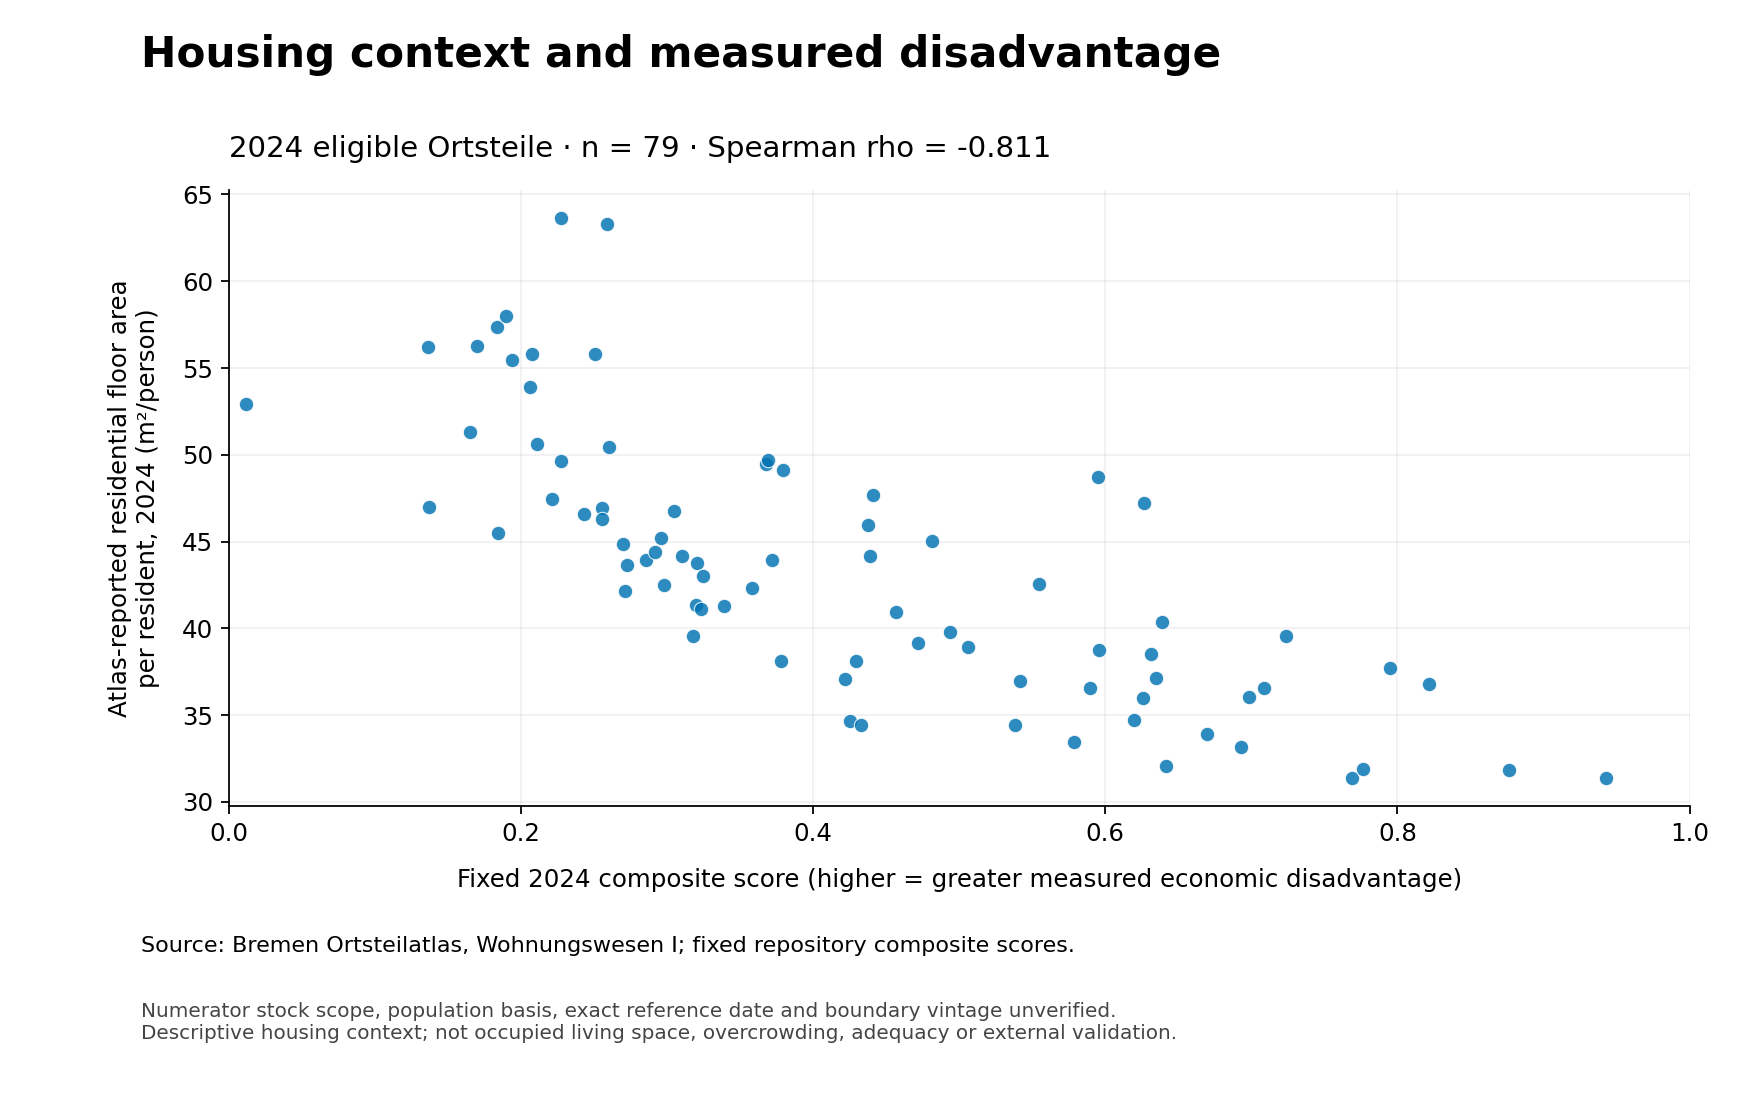

In [8]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})
fig, ax = plt.subplots(figsize=(11, 7))
fig.subplots_adjust(left=0.13, right=0.96, bottom=0.28, top=0.83)
fig.suptitle('Housing context and measured disadvantage', x=0.08, y=0.97,
             ha='left', fontsize=19, fontweight='bold')
ax.set_title(f'2024 eligible Ortsteile · n = {len(x)} · Spearman rho = {rho:.3f}', loc='left', pad=15)
points = ax.scatter(x, y, color='#0072B2', s=42, alpha=0.82, edgecolors='white', linewidths=0.5)
np.testing.assert_allclose(points.get_offsets(),
    saved_housing[['composite_score', 'floor_area_m2_per_resident']], rtol=0, atol=1e-12)
ax.set_xlim(0, 1)
ax.set_xlabel('Fixed 2024 composite score (higher = greater measured economic disadvantage)', labelpad=10)
ax.set_ylabel('Atlas-reported residential floor area\nper resident, 2024 (m²/person)', labelpad=10)
ax.grid(alpha=0.18)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
fig.text(0.08, 0.15, 'Source: Bremen Ortsteilatlas, Wohnungswesen I; fixed repository composite scores.', fontsize=10)
fig.text(0.08, 0.105, 'Numerator stock scope, population basis, exact reference date and boundary vintage unverified.\n'
         'Descriptive housing context; not occupied living space, overcrowding, adequacy or external validation.',
         fontsize=9, color='#444444', va='top')
image = BytesIO()
fig.savefig(image, format='png', dpi=160)
plt.close(fig)
display(Image(data=image.getvalue()))

## 5. Results, limits and reproduction

The calculated summary below distinguishes mathematical reproduction from source-definition uncertainty. Leave-one-out ranges describe omission sensitivity, **not confidence intervals**. No conventional housing p-values are used: this is an unweighted descriptive association among the fixed 79 eligible areas, with spatial dependence and complete-case selection limitations. Negative association means higher measured disadvantage accompanies lower **Atlas-reported** area per resident; it does not explain why.

**Provenance:** `analysis/source_manifest.csv` records original input hashes; `data/processed/section2_indicator_metadata.csv` records indicator provenance and unresolved definitions. Official geometry snapshots and provenance are in `reports/section2_v2/atlas/sources/`, with guards in `src/build_section2_atlas.py`. The spatial and housing saved CSVs are checked numerically above; the scatter coordinates are checked against the housing CSV, without rewriting its saved PNG. Related reproducible scripts are `analysis/part2/fieldwork_sampling.py`, `spatial_autocorrelation.py` and `housing_benchmark.py`.

**Reproduce:** select the existing project Python kernel in VS Code, open this notebook from `notebooks/` or the root, and Restart Kernel → Run All. Keep the processed inputs, saved results and archived geometry together. All assertions must pass; changed sources or results require review rather than silently accepting a new baseline. No generator, packaging or output-writing script is called. Package versions and the authoring execution status are recorded in notebook metadata.

**For presentation:** retain the eligibility count, proposed-visit label and housing caveat; do not turn spatial dependence into a transport-accessibility claim, method agreement into external validation, or these cross-sectional associations into causality.

**Authoring validation:** all code cells executed in order using a controlled IPython fallback in an isolated repository copy. Full Jupyter execution is **NOT VERIFIED**: Windows denied connection-file ACL setup (WinError 5). This is an environment startup failure, not a successful kernel run. Re-run with the project kernel in VS Code before relying on full Jupyter compatibility.

In [9]:
manifest = read('analysis/source_manifest.csv')
assert len(manifest) == 24
assert all(sha256((ROOT / r.file).read_bytes()).hexdigest() == r.sha256 for r in manifest.itertuples())
spatial_text = '; '.join(f"k={k}: I={row['Moran I']:.6f}, Monte Carlo p={row['Monte Carlo p']:.4f}"
                         for k, row in spatial_results.iterrows())
display(Markdown(
    f'- **Coverage:** {len(sample)} of {len(base)} Ortsteile eligible; {len(base)-len(sample)} excluded.\n'
    f'- **Fieldwork:** {len(shortlist)} proposed candidates; no completed visits are evidenced here.\n'
    f'- **Spatial pattern:** {spatial_text}; E[I]={expected:.6f}.\n'
    f'- **Housing:** Spearman rho={rho:.6f}; all {len(loo)} omissions verified; '
    f'LOO range [{loo.min():.6f}, {loo.max():.6f}].\n'
    '- **Interpretation:** clustering and a negative descriptive housing-context association; '
    'neither causality nor independent external validation.\n'
    f'- **Reproduction:** {len(manifest)} original source hashes and all numerical checks passed (tolerance 1e-12).'))

- **Coverage:** 79 of 88 Ortsteile eligible; 9 excluded.
- **Fieldwork:** 5 proposed candidates; no completed visits are evidenced here.
- **Spatial pattern:** k=4: I=0.299181, Monte Carlo p=0.0001; k=6: I=0.200721, Monte Carlo p=0.0011; E[I]=-0.012821.
- **Housing:** Spearman rho=-0.811190; all 79 omissions verified; LOO range [-0.832869, -0.803892].
- **Interpretation:** clustering and a negative descriptive housing-context association; neither causality nor independent external validation.
- **Reproduction:** 24 original source hashes and all numerical checks passed (tolerance 1e-12).